# 02 · Frontalization: removing head pose

Head pose moves 2-D landmarks far more than many expressions do. Frontalization
([Vonikakis & Winkler, ICIP 2020](https://stefan.winkler.site/Publications/icip2020a.pdf))
maps a Procrustes-normalised shape to an estimate of its frontal view with **one linear map**.
This notebook:

1. explores the multi-pose training data;
2. retrains the map with person-grouped cross-validation, comparing the 2021 mirroring
   augmentation with none;
3. measures what matters downstream: how much the arousal/valence estimate moves when the
   head turns, with and without frontalization;
4. retrains the final weights on all data and checks them against the bundled file.

Full script: `experiments/07_frontalization.py`. Runtime: about 2 minutes.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
ROOT = Path.cwd() if (Path.cwd() / "examples").is_dir() else Path.cwd().parent  # repo root

from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GroupKFold

from facial_expression_analysis import Frontalizer, PairwiseDistanceFeatures, procrustes_normalize
from facial_expression_analysis.frontalization import DEFAULT_WEIGHTS
from facial_expression_analysis.training.data import load_morphset
from facial_expression_analysis.training.frontalization import (
    MirrorMode,
    align_parts_to_template,
    assign_pose_persons,
    build_training_pairs,
    fit_frontalization,
    frontalization_error,
    load_pose_dataset,
    mean_shape,
)
from facial_expression_analysis.viz import plot_landmarks

## 1. The multi-pose dataset

42,834 landmark shapes in three families with different camera grids and expressions. The
families identify their source databases (Multi-PIE, KDEF and, most likely, CAS-PEAL). Subject
ids repeat per session, so persons are re-derived from neutral-face geometry, as for MorphSet.

In [2]:
pose = load_pose_dataset()
meta = pose.meta
persons = assign_pose_persons(pose)
print(
    f"{len(pose):,} shapes, {meta.subject.nunique():,} subject ids, {len(set(persons)):,} persons"
)
meta.groupby("family").agg(
    shapes=("subject", "size"),
    subjects=("subject", "nunique"),
    yaws=("yaw", lambda s: sorted(s.abs().unique().astype(int).tolist())),
    expressions=("expression", lambda s: " ".join(sorted(s.unique()))),
)

42,834 shapes, 2,169 subject ids, 1,202 persons


,shapes,subjects,yaws,expressions
family,,,,
caspeal,3851,169,"[0, 22, 45, 67, 90]",HA NE SL
kdef,2931,140,"[0, 45]",AF AN DI HA NE SA SU
multipie,36052,1860,"[0, 15, 30, 45, 60]",DI HA NE SC SQ SU


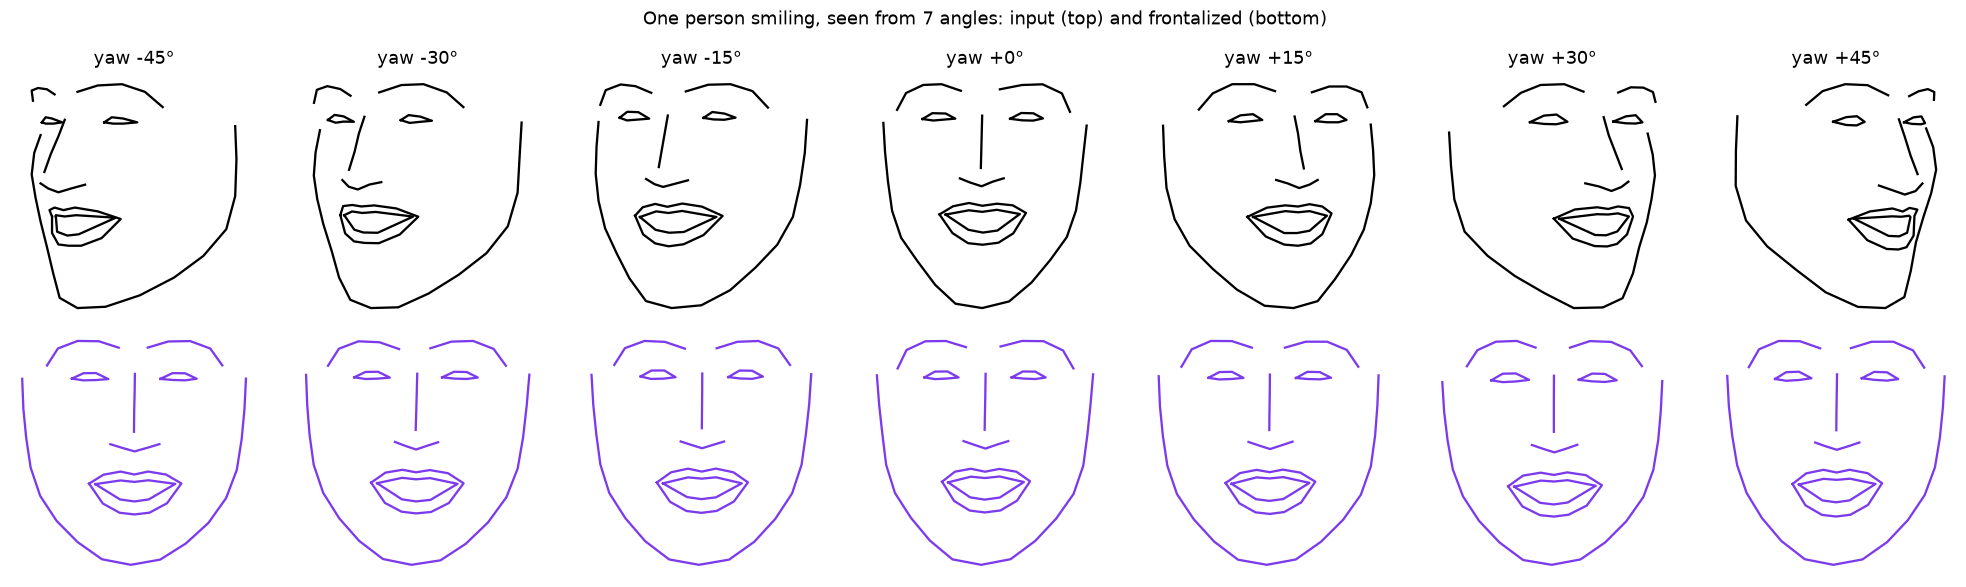

In [3]:
mp = meta[(meta.family == "multipie") & (meta.pitch == 0) & (meta.expression == "HA")]
subject = next(s for s, g in mp.groupby("subject") if {0, 15, 30, 45} <= set(g.yaw.abs()))
views = mp[mp.subject == subject].drop_duplicates("yaw").sort_values("yaw")
views = views[views.yaw.abs().isin([0, 15, 30, 45])]
front = Frontalizer()
fig, axes = plt.subplots(2, len(views), figsize=(2.6 * len(views), 5.4))
for k, (i, row) in enumerate(views.iterrows()):
    plot_landmarks(
        procrustes_normalize(pose.landmarks[i]), axes[0, k], title=f"yaw {row.yaw:+.0f}°"
    )
    plot_landmarks(front(pose.landmarks[i]), axes[1, k], color="#7c3aed")
axes[0, 0].set_ylabel("input")
axes[1, 0].set_ylabel("frontalized")
fig.suptitle(
    f"One person smiling, seen from {len(views)} angles: input (top) and frontalized (bottom)"
)
plt.tight_layout()

## 2. Retraining with person-grouped cross-validation

Each posed shape is paired with the frontal shape of the same person and expression. The
targets are made **identity-invariant**: each facial part is moved to its position in a mean
face (the template), which is fitted on training persons only. The map is ordinary least
squares on `[x₁…x₆₈, y₁…y₆₈, 1]` (137 inputs → 136 outputs).

The 2021 model added mirrored copies by negating x only (`naive`), which swaps the
left/right meaning of the landmark ids. `permute` mirrors correctly; `none` adds no copies.
Error is the mean landmark distance to the target, on held-out persons' real (non-mirrored)
shapes, in units of the normalised face size.

yaw,0,15,22,30,45,67
model,,,,,,
"linear map, mirror=naive",0.027,0.029,0.034,0.032,0.039,0.045
"linear map, mirror=none",0.024,0.027,0.032,0.030,0.036,0.042
"linear map, mirror=permute",0.025,0.027,0.032,0.030,0.037,0.043
no correction,0.089,0.140,0.165,0.209,0.259,0.232
parts moved to template only,0.020,0.067,0.084,0.108,0.134,0.119


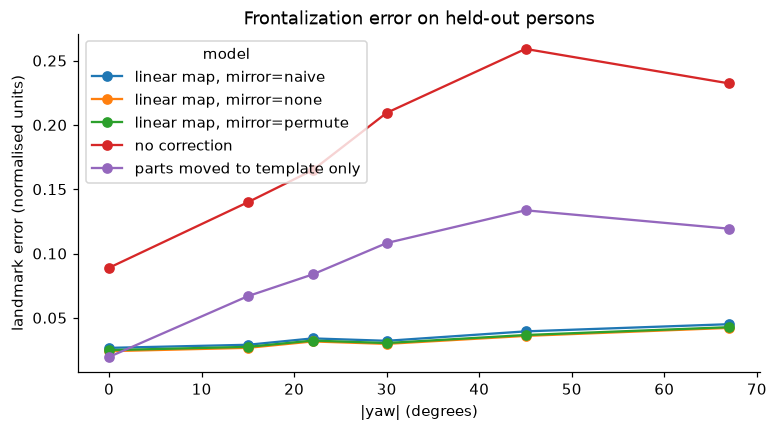

In [4]:
rows = []
folds = list(GroupKFold(5, shuffle=True, random_state=0).split(pose.landmarks, groups=persons))
weights_fold0 = {}
for fold, (tr, te) in enumerate(folds):
    train, test = (
        pose.subset(np.isin(np.arange(len(pose)), tr)),
        pose.subset(np.isin(np.arange(len(pose)), te)),
    )
    template = mean_shape(train.landmarks)
    tp = build_training_pairs(test, template, MirrorMode.NONE)
    yaw = test.meta.yaw.abs().to_numpy()[tp.row]
    variants = {
        "no correction": tp.inputs,
        "parts moved to template only": align_parts_to_template(tp.inputs, template),
    }
    for mode in MirrorMode:
        W = fit_frontalization(build_training_pairs(train, template, mode))
        variants[f"linear map, mirror={mode.value}"] = Frontalizer(W)(tp.inputs)
        if fold == 0:
            weights_fold0[mode] = W
    for name, pred in variants.items():
        err = frontalization_error(pred, tp.targets)
        rows += [
            {"fold": fold, "model": name, "yaw": y, "error": err[yaw == y].mean()}
            for y in (0, 15, 22, 30, 45, 67)
        ]
err = pd.DataFrame(rows).groupby(["model", "yaw"]).error.mean().unstack()
ax = err.T.plot(marker="o", figsize=(8, 4))
ax.set(
    xlabel="|yaw| (degrees)",
    ylabel="landmark error (normalised units)",
    title="Frontalization error on held-out persons",
)
err.round(4)

In [5]:
naive, none = err.loc["linear map, mirror=naive"], err.loc["linear map, mirror=none"]
print("no mirroring vs 2021 naive mirroring: error change by yaw (%)")
((none / naive - 1) * 100).round(1).to_frame("change %").T

no mirroring vs 2021 naive mirroring: error change by yaw (%)


yaw,0,15,22,30,45,67
change %,-9.7,-8.2,-7.0,-7.4,-8.9,-6.4


The linear map removes most of the pose error at every angle, and the naive mirroring of 2021
hurts: training on mirror images whose left/right ids are swapped teaches the map an inconsistent
geometry. Correct mirroring (`permute`) and none perform about the same, so v2 uses none,
the simplest option.

## 3. What matters: does the emotion estimate stay put when the head turns?

For held-out persons (Multi-PIE and CAS-PEAL only, because KDEF persons are also in
MorphSet), we compare the prediction for each posed face with the prediction for the frontal
face of the same person and expression. Two PLS(31) emotion models are trained on MorphSet:
one on raw Procrustes shapes, one on shapes frontalized by the fold-0 map (fitted without these
test persons).

In [6]:
%%time
morph = load_morphset()
feats = PairwiseDistanceFeatures()
test = pose.subset(np.isin(np.arange(len(pose)), folds[0][1]))
tm = test.meta.reset_index(drop=True)
frontal = (tm.yaw == 0) & (tm.pitch == 0)
key = tm.subject.astype(str) + "|" + tm.expression
ref = key.map(tm.index.to_series()[frontal].groupby(key[frontal]).first())
ok = (
    ref.notna()
    & ~frontal
    & (tm.pitch == 0)
    & tm.yaw.abs().isin([15, 22, 30, 45])
    & (tm.family != "kdef")
)
posed, refs = np.flatnonzero(ok), ref[ok].to_numpy(dtype=int)

pipelines = {
    "no frontalization": procrustes_normalize,
    "frontalized": Frontalizer(weights_fold0[MirrorMode.NONE]),
}
shift = []
for name, f in pipelines.items():
    pls = PLSRegression(31).fit(feats(f(morph.landmarks)), morph.targets)
    d = np.abs(
        np.clip(pls.predict(feats(f(test.landmarks[posed]))), -1, 1)
        - np.clip(pls.predict(feats(f(test.landmarks[refs]))), -1, 1)
    )
    shift.append(
        pd.DataFrame(
            {"pipeline": name, "yaw": tm.yaw.abs().to_numpy()[posed], "ΔA": d[:, 0], "ΔV": d[:, 1]}
        )
    )
shift = pd.concat(shift).groupby(["pipeline", "yaw"])[["ΔA", "ΔV"]].mean().unstack("pipeline")
shift.round(3)

CPU times: user 1min 54s, sys: 1.19 s, total: 1min 56s
Wall time: 1min 55s


ΔA                            ΔV                  
pipeline frontalized no frontalization frontalized no frontalization
yaw                                                                 
15.0           0.066             0.113       0.118             0.147
22.0           0.070             0.128       0.107             0.128
30.0           0.084             0.292       0.146             0.183
45.0           0.100             0.574       0.189             0.242

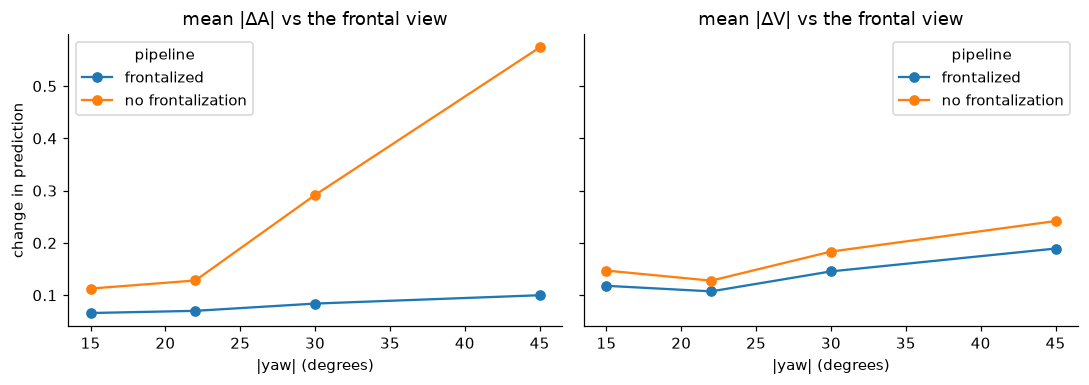

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, target in zip(axes, ["ΔA", "ΔV"], strict=True):
    shift[target].plot(ax=ax, marker="o")
    ax.set(xlabel="|yaw| (degrees)", title=f"mean |{target}| vs the frontal view")
axes[0].set_ylabel("change in prediction")
plt.tight_layout()

Without frontalization, turning the head by 45° moves the arousal estimate by about half
the scale, as much as a strong expression. With frontalization the shift stays near its
frontal level (≈0.1), most of which is the difference between two separate photos.

## 4. Final weights

The bundled weights are the same least-squares fit on **all** persons, with no mirroring.
`fea train-frontalization` does exactly this.

In [8]:
template = mean_shape(pose.landmarks)
W = fit_frontalization(build_training_pairs(pose, template, MirrorMode.NONE))
bundled = Frontalizer._load_bundled()
print(
    f"weights {W.shape}; max |difference| to the bundled {DEFAULT_WEIGHTS}: {np.abs(W - bundled).max():.2e}"
)
# To use your own weights:   Frontalizer(W)   or   np.save("models/frontalization.npy", W)

weights (137, 136); max |difference| to the bundled frontalization_dlib68.npy: 0.00e+00


**Next:** notebook 03 builds the features on frontalized shapes and selects the regressor.